# SciPulse — Analyse de la qualité des données

Ce notebook documente l'**analyse qualité de la couche Bronze** qui a guidé le
nettoyage Silver, puis les **statistiques descriptives** des données nettoyées.

1. Chargement des données (MinIO)
2. ArXiv — valeurs manquantes, types, doublons, incohérences
3. Hacker News — schémas hétérogènes, snapshots, valeurs manquantes
4. OpenAlex — couverture et distribution des citations
5. Procédure de nettoyage (anomalie → règle → code)
6. Statistiques descriptives Silver
7. Résultats Great Expectations

**Prérequis** : stack démarrée, pipeline exécuté au moins une fois,
`pip install -r requirements-notebook.txt`.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

# Identifiants lus dans .env (jamais écrits dans le notebook)
env = dict(line.split("=", 1) for line in (ROOT / ".env").read_text(encoding="utf-8").splitlines()
           if "=" in line and not line.startswith("#"))

from scipulse.config import Bucket, Settings
from scipulse.storage import DataLake

lake = DataLake.from_settings(Settings(s3_endpoint_url="http://localhost:9000",
                                       s3_access_key=env["MINIO_ROOT_USER"],
                                       s3_secret_key=env["MINIO_ROOT_PASSWORD"]))
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_colwidth", 80)

## 1. Chargement des données Bronze

Lecture des JSON Lines bruts, tels qu'ingérés (aucune transformation).

In [2]:
arxiv_raw = pd.DataFrame(lake.iter_records(Bucket.ARXIV_RAW, "arxiv/"))
hn_env = list(lake.iter_records(Bucket.HN_RAW))
works_raw = pd.DataFrame(lake.iter_records(Bucket.CITATIONS_RAW, "openalex/"))
print(f"ArXiv Bronze      : {len(arxiv_raw):>7,} enregistrements, {arxiv_raw.shape[1]} champs")
print(f"Hacker News Bronze: {len(hn_env):>7,} enveloppes (snapshots inclus)")
print(f"OpenAlex Bronze   : {len(works_raw):>7,} works")
arxiv_raw.head(3)

ArXiv Bronze      : 100,000 enregistrements, 14 champs
Hacker News Bronze:  37,315 enveloppes (snapshots inclus)
OpenAlex Bronze   : 110,899 works


,id,submitter,authors,title,comments,journal-ref,doi,report-no,categories,license,abstract,versions,update_date,authors_parsed
0,1501.00265,Slavcho Shtrakov,Sl. Shtrakov and I. Damyanov,On the complexity of finite valued functions,"23 pages, 4 figures, 6 tables, Preprint of the article is submitted\n for c...",None,None,None,cs.CC,http://creativecommons.org/licenses/by/3.0/,The essential variables in a finite function $f$ are defined as variables\...,"[{'version': 'v1', 'created': 'Thu, 1 Jan 2015 09:47:02 GMT'}]",2015-01-05,"[[Shtrakov, Sl., ], [Damyanov, I., ]]"
1,1501.00311,Jun Ping Ng,Jun-Ping Ng and Min-Yen Kan,QANUS: An Open-source Question-Answering Platform,"6 pages, 3 figures, demo paper describing QANUS",None,None,None,cs.IR cs.CL,http://arxiv.org/licenses/nonexclusive-distrib/1.0/,"In this paper, we motivate the need for a publicly available, generic\nsof...","[{'version': 'v1', 'created': 'Thu, 1 Jan 2015 20:51:25 GMT'}]",2015-01-05,"[[Ng, Jun-Ping, ], [Kan, Min-Yen, ]]"
2,1501.00312,Po-Ling Loh,Po-Ling Loh,Statistical consistency and asymptotic normality for high-dimensional\n rob...,"56 pages, 8 figures",None,None,None,math.ST cs.IT math.IT stat.ML stat.TH,http://arxiv.org/licenses/nonexclusive-distrib/1.0/,"We study theoretical properties of regularized robust M-estimators,\nappli...","[{'version': 'v1', 'created': 'Thu, 1 Jan 2015 20:52:30 GMT'}]",2015-01-05,"[[Loh, Po-Ling, ]]"


## 2. ArXiv

### 2.1 Valeurs manquantes

Les chaînes vides sont comptées comme manquantes : elles portent la même
absence d'information qu'un `null`.

In [3]:
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    empty = df.apply(lambda col: col.map(lambda v: v is None or (isinstance(v, str) and not v.strip())
                                         or (isinstance(v, float) and np.isnan(v))))
    report = pd.DataFrame({"manquants": empty.sum(), "pct": (100 * empty.mean()).round(2)})
    return report.sort_values("pct", ascending=False)

arxiv_missing = missing_report(arxiv_raw.drop(columns=["versions", "authors_parsed"]))
arxiv_missing

,manquants,pct
report-no,99237,99.24
journal-ref,89622,89.62
doi,84537,84.54
comments,43393,43.39
id,0,0.00
submitter,0,0.00
authors,0,0.00
title,0,0.00
categories,0,0.00
license,0,0.00


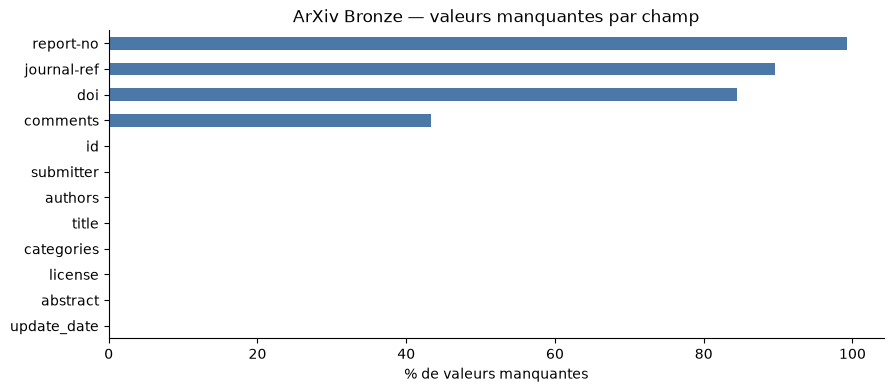

In [4]:
ax = arxiv_missing["pct"].plot.barh(color="#4c78a8")
ax.set_xlabel("% de valeurs manquantes"); ax.set_title("ArXiv Bronze — valeurs manquantes par champ")
ax.invert_yaxis(); plt.show()

**Lecture** : `title`, `abstract`, `id`, `categories` sont complets — les
champs critiques pour la recherche et la jointure. Les champs éditoriaux
(`journal-ref`, `doi`, `report-no`, `comments`) sont très souvent absents :
c'est attendu pour des *preprints*, ce n'est pas une erreur. Conséquence : le
DOI éditeur ne peut pas être la clé de jointure principale → on construit le
**DOI ArXiv** (`10.48550/arxiv.<id>`), disponible pour 100 % des articles.

### 2.2 Types et formats

In [5]:
checks = {
    "id au format ArXiv": arxiv_raw["id"].str.match(r"^(\d{4}\.\d{4,5}|[a-z\-]+(\.[A-Z]{2})?/\d{7})$"),
    "update_date AAAA-MM-JJ": arxiv_raw["update_date"].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$"),
    "versions[0].created RFC 2822": arxiv_raw["versions"].map(
        lambda v: bool(v) and bool(re.match(r"^\w{3}, \d{1,2} \w{3} \d{4}", v[0].get("created", "")))),
    "categories = chaîne d'étiquettes": arxiv_raw["categories"].map(lambda c: isinstance(c, str)),
}
pd.DataFrame({"conformes %": {k: round(100 * s.mean(), 3) for k, s in checks.items()}})

,conformes %
categories = chaîne d'étiquettes,100.0
id au format ArXiv,100.0
update_date AAAA-MM-JJ,100.0
versions[0].created RFC 2822,100.0


Deux formats de date coexistent (`update_date` ISO, `versions[].created` en
RFC 2822 avec nom du jour en anglais) → **normalisation en horodatage UTC**.
Les catégories sont une chaîne séparée par des espaces (`"cs.LG stat.ML"`) →
**liste + catégorie primaire + domaine + libellé lisible**.

### 2.3 Doublons

In [6]:
dup_ids = arxiv_raw["id"].duplicated().sum()
dup_titles = arxiv_raw["title"].str.lower().str.replace(r"\s+", " ", regex=True).duplicated().sum()
print(f"Identifiants dupliqués : {dup_ids}")
print(f"Titres dupliqués (normalisés) : {dup_titles}")
arxiv_raw[arxiv_raw["title"].str.lower().str.replace(r"\s+", " ", regex=True)
          .duplicated(keep=False)].sort_values("title")[["id", "title", "update_date"]].head(10)

Identifiants dupliqués : 0
Titres dupliqués (normalisés) : 3


,id,title,update_date
45714,2209.10168,Improving Generalizability of Graph Anomaly Detection Models via Data\n Aug...,2023-07-25
54088,2306.10534,Improving Generalizability of Graph Anomaly Detection Models via Data\n Aug...,2023-06-21
62142,2402.05306,Interactive Symbolic Regression through Offline Reinforcement Learning:\n A...,2025-02-14
77388,2502.02917,Interactive Symbolic Regression through Offline Reinforcement Learning:\n A...,2025-02-12
5229,1701.02810,OpenNMT: Open-Source Toolkit for Neural Machine Translation,2017-03-07
7669,1709.03815,OpenNMT: Open-source Toolkit for Neural Machine Translation,2017-09-13


L'échantillonnage garantit l'unicité des identifiants sur un run ; des
doublons d'id apparaissent en revanche en cas de **ré-ingestion** (plusieurs
runs Bronze conservés pour l'historique) → Silver déduplique sur `arxiv_id`
en gardant la **mise à jour la plus récente**. Des titres identiques avec des
id différents sont des articles distincts (erratum, versions de conférence) :
ils sont conservés.

### 2.4 Incohérences : les DOI

In [7]:
doi = arxiv_raw["doi"].dropna().astype(str)
anomalies = pd.DataFrame({
    "plusieurs DOI dans le champ": doi.str.contains(r"\s"),
    "échappement LaTeX (\\_)": doi.str.contains(r"\\"),
    "majuscules": doi.str.contains(r"[A-Z]"),
    "préfixe https://doi.org": doi.str.contains("doi.org"),
}).sum().to_frame("occurrences")
anomalies

,occurrences
plusieurs DOI dans le champ,17
échappement LaTeX (\_),4
majuscules,6257
préfixe https://doi.org,0


In [8]:
doi[doi.str.contains(r"\s|\\")].head(8).to_frame("exemples de DOI anormaux")

,exemples de DOI anormaux
1624,10.1007/s00224-017-9763-z 10.1007/978-3-319-34171-2_17
1696,10.1109/LWC.2015.2487960 10.1109/LWC.2015.2487960
10391,10.1007/s00453-020-00675-w 10.4230/LIPIcs.ISAAC.2018.5
15821,10.3906/mat-1912-106 10.1109/ISIT.2019.8849819
23628,10.1134/S0037446621050165 10.33048/smzh.2021.62.516
29627,10.1145/3442188.3445941 10.1145/3442188.3445941 10.1145/3442188.3445941\n 1...
31856,10.1145/3490486.3538321 10.1016/j.artint.2023.103904
32127,10.1137/21M1417077 10.1007/978-3-030-83823-2_135


**Anomalie réelle découverte en production** : ces DOI ont fait échouer les
requêtes OpenAlex (erreur 400 sur un lot entier). Corrections :
- Silver (`silver/keys.py::normalize_doi`) : premier DOI du champ, suppression
  des `\`, minuscules, sans préfixe `https://doi.org/` ;
- Bronze OpenAlex : découpage dichotomique d'un lot refusé pour isoler le DOI
  fautif sans perdre les autres.

### 2.5 Distributions

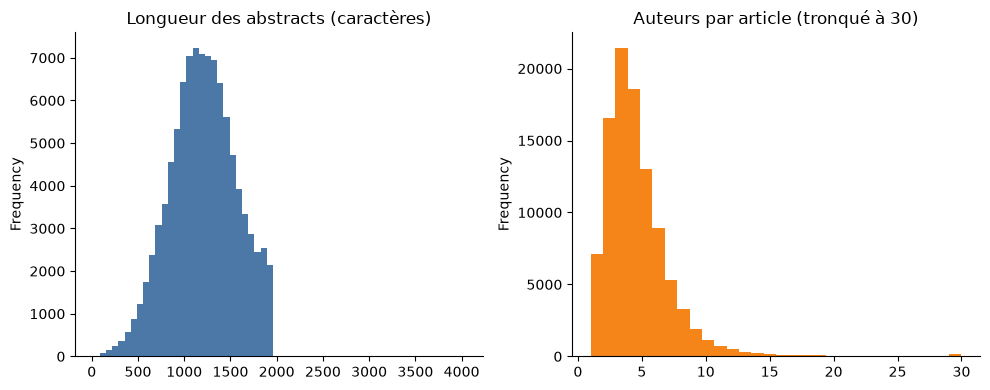

count    100000.0
mean       1207.0
std         356.0
min          21.0
25%         966.0
50%        1205.0
75%        1455.0
max        4031.0

Abstracts < 50 caractères : 3  |  articles > 100 auteurs : 15


In [9]:
lengths = arxiv_raw["abstract"].fillna("").str.len()
fig, axes = plt.subplots(1, 2)
lengths.plot.hist(bins=60, ax=axes[0], color="#4c78a8")
axes[0].set_title("Longueur des abstracts (caractères)")
n_authors = arxiv_raw["authors_parsed"].map(len)
n_authors.clip(upper=30).plot.hist(bins=30, ax=axes[1], color="#f58518")
axes[1].set_title("Auteurs par article (tronqué à 30)")
plt.tight_layout(); plt.show()
print(lengths.describe().round(0).to_string())
print(f"\nAbstracts < 50 caractères : {(lengths < 50).sum()}  |  "
      f"articles > 100 auteurs : {(n_authors > 100).sum()}")

Les abstracts très courts sont rares (retraits, *withdrawn*) : l'expectation
`abstract` entre 50 et 10 000 caractères est donc posée avec `mostly=0.99`.
Les articles à centaines d'auteurs sont légitimes (grandes collaborations) :
borne haute à 5 000.

## 3. Hacker News

In [10]:
hn_raw = pd.DataFrame([{**e["payload"], "_source": e["_source"], "_ingested_at": e["_ingested_at"]}
                       for e in hn_env])
print(hn_raw["_source"].value_counts().to_string())
fields = {"firebase": ["id", "title", "url", "score", "descendants", "time", "by"],
          "algolia": ["objectID", "title", "url", "points", "num_comments", "created_at_i", "author"]}
pd.DataFrame({src: (100 * hn_raw.loc[hn_raw._source == src, cols].isna().mean()).round(2)
                    .set_axis(["id", "titre", "url", "score", "commentaires", "date", "auteur"])
              for src, cols in fields.items()})

_source
algolia     23272
firebase    14043


,firebase,algolia
id,0.00,0.0
titre,0.00,0.0
url,3.08,0.0
score,0.00,0.0
commentaires,0.00,0.0
date,0.00,0.0
auteur,0.00,0.0


- **Deux schémas** pour la même entité (`id`/`objectID`, `score`/`points`,
  `descendants`/`num_comments`) → schéma unifié en Silver.
- `url` manquante = *Ask HN* / *Show HN* sans lien : légitime.
- Scores / commentaires manquants = story sans vote → **0**.

In [11]:
hn_ids = hn_raw["id"].fillna(hn_raw["objectID"]).astype("int64")
snapshots = hn_ids.value_counts()
print(f"Stories distinctes : {snapshots.size:,}  |  enveloppes : {len(hn_ids):,}")
print(f"Stories capturées plusieurs fois (snapshots du poller) : {(snapshots > 1).sum():,}")
from scipulse.silver.keys import arxiv_id_from_url
linked = hn_raw["url"].map(arxiv_id_from_url).notna()
print(f"Stories avec un identifiant ArXiv extrait de l'URL : {linked.sum():,}")

Stories distinctes : 24,353  |  enveloppes : 37,315
Stories capturées plusieurs fois (snapshots du poller) : 1,076


Stories avec un identifiant ArXiv extrait de l'URL : 23,145


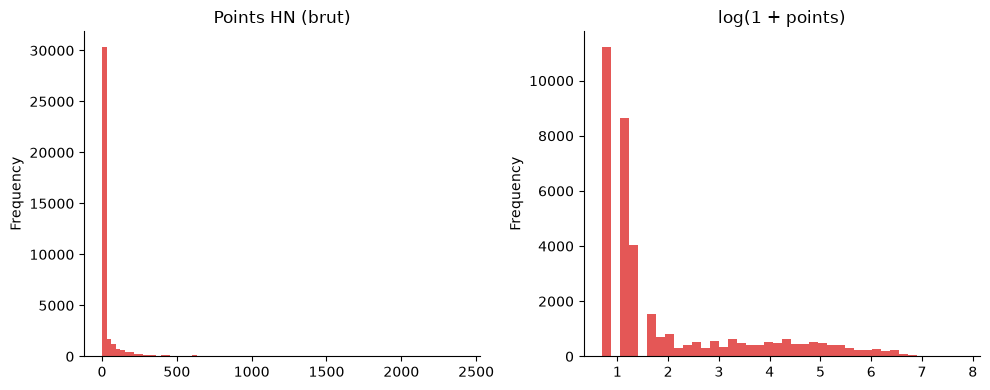

In [12]:
points = hn_raw["score"].fillna(hn_raw["points"]).fillna(0)
fig, axes = plt.subplots(1, 2)
points.plot.hist(bins=80, ax=axes[0], color="#e45756"); axes[0].set_title("Points HN (brut)")
np.log1p(points).plot.hist(bins=40, ax=axes[1], color="#e45756"); axes[1].set_title("log(1 + points)")
plt.tight_layout(); plt.show()

Distribution **extrêmement asymétrique** (quelques stories à plusieurs
milliers de points, la majorité sous 10) → le signal HN du score d'impact est
**log-scalé**.

## 4. OpenAlex

works : 110,899  |  sans DOI : 0  |  doublons d'id : 14388
count    110899.0
mean         24.6
std         149.1
min           0.0
50%           3.0
90%          45.0
99%         337.0
max       13310.0


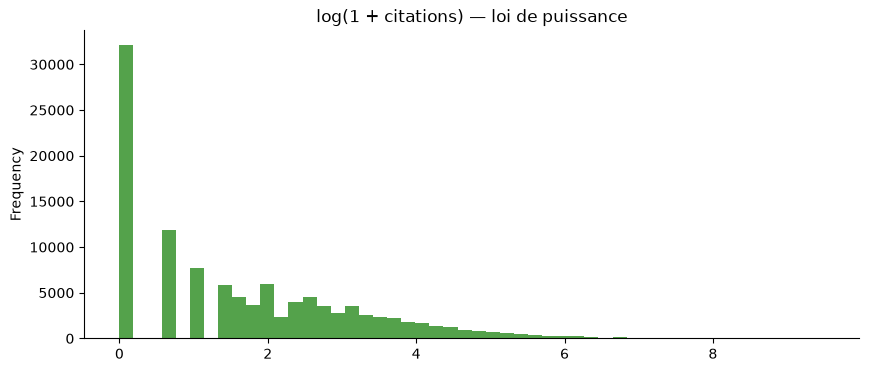

In [13]:
cited = works_raw["cited_by_count"].fillna(0)
print(f"works : {len(works_raw):,}  |  sans DOI : {works_raw['doi'].isna().sum()}  |  "
      f"doublons d'id : {works_raw['id'].duplicated().sum()}")
print(cited.describe(percentiles=[.5, .9, .99]).round(1).to_string())
ax = np.log1p(cited).plot.hist(bins=50, color="#54a24b")
ax.set_title("log(1 + citations) — loi de puissance"); plt.show()

Citations en **loi de puissance** (médiane faible, quelques articles à
dizaines de milliers) → le score utilise un **rang centile** par cohorte
d'année plutôt que la valeur brute. Les doublons d'id viennent d'un même work
renvoyé pour son DOI ArXiv *et* son DOI éditeur → dédupliqués en Silver.

## 5. Procédure de nettoyage

| Source | Anomalie constatée | Règle Silver | Code |
|---|---|---|---|
| ArXiv | Doublons d'id (ré-ingestion) | Garder la mise à jour la plus récente | `silver/arxiv.py::build_silver` |
| ArXiv | Retours à la ligne / espaces multiples | Normalisation des espaces | `clean_text` |
| ArXiv | Dates RFC 2822 et ISO | Horodatages UTC | `parse_rfc2822` |
| ArXiv | Catégories en chaîne | Liste, primaire, domaine, libellé | `clean_record` |
| ArXiv | Auteurs `[nom, prénom, suffixe]` | « Prénom Nom » + nombre | `parse_authors` |
| ArXiv | DOI multiples / échappés / majuscules | Premier DOI normalisé | `silver/keys.py::normalize_doi` |
| ArXiv | id / titre invalide | Ligne rejetée (comptée en métrique) | `clean_record` |
| HN | Deux schémas sources | Schéma unifié | `silver/hn.py::PARSERS` |
| HN | Snapshots multiples | Snapshot le plus récent | `build_silver` |
| HN | Score / commentaires manquants | 0 | `build_silver` |
| HN | Lien ArXiv dans l'URL | `arxiv_id` extrait (clé de jointure) | `keys.py::arxiv_id_from_url` |
| OpenAlex | id URL longue | Identifiant court `W…` | `silver/citations.py` |
| OpenAlex | Work dupliqué (2 DOI) | Dédupliqué par id | `build_silver` |

Toute sortie Silver passe par la **porte qualité** (`silver/gate.py`) :
validation GX avant publication, Silver non écrasé en cas d'échec.

## 6. Statistiques descriptives Silver

In [14]:
arxiv = lake.read_parquet(Bucket.ARXIV_CLEAN, "arxiv/")
hn = lake.read_parquet(Bucket.HN_CLEAN, "hn/")
cit = lake.read_parquet(Bucket.CITATIONS_CLEAN, "openalex/")
print(f"Silver : ArXiv {len(arxiv):,} | HN {len(hn):,} | citations {len(cit):,}")
arxiv[["n_authors", "n_versions", "published_year"]].describe().round(2)

Silver : ArXiv 100,000 | HN 24,270 | citations 96,511


,n_authors,n_versions,published_year
count,100000.00,100000.00,100000.0
mean,4.35,1.60,2022.01
std,3.99,0.99,2.86
min,1.00,1.00,2015.0
25%,3.00,1.00,2020.0
50%,4.00,1.00,2023.0
75%,5.00,2.00,2024.0
max,438.00,22.00,2026.0


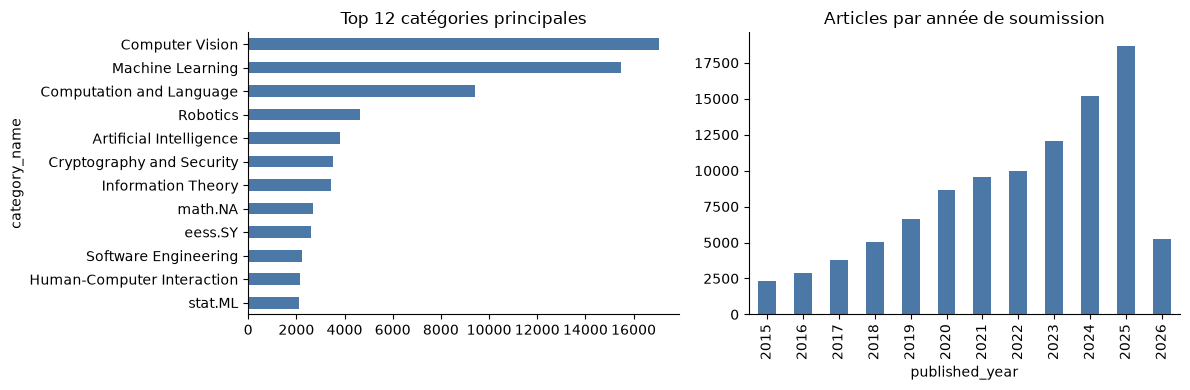

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
arxiv["category_name"].value_counts().head(12).iloc[::-1].plot.barh(ax=axes[0], color="#4c78a8")
axes[0].set_title("Top 12 catégories principales")
arxiv.groupby("published_year").size().plot.bar(ax=axes[1], color="#4c78a8")
axes[1].set_title("Articles par année de soumission")
plt.tight_layout(); plt.show()

Forte croissance depuis 2022 (essor des LLM). La baisse de la dernière année
est un **artefact de collecte** (année en cours au moment du téléchargement du
dump), pas une tendance.

In [16]:
links = hn.dropna(subset=["arxiv_id"])
print(f"Stories HN liées à ArXiv : {len(links):,} ({100 * len(links) / len(hn):.1f} %)")
in_sample = links["arxiv_id"].isin(arxiv["arxiv_id"])
print(f"… dont l'article est dans l'échantillon : {in_sample.sum():,}")
cov = arxiv["arxiv_doi"].isin(cit["doi"]) | arxiv["journal_doi"].isin(cit["doi"])
print(f"Articles ArXiv avec un work OpenAlex : {cov.sum():,} ({100 * cov.mean():.1f} %)")

Stories HN liées à ArXiv : 23,060 (95.0 %)
… dont l'article est dans l'échantillon : 2,132
Articles ArXiv avec un work OpenAlex : 61,269 (61.3 %)


## 7. Résultats Great Expectations

In [17]:
metrics = pd.concat(pd.read_json(p, lines=True) for p in sorted((ROOT / "data" / "metrics").glob("*.jsonl")))
silver = metrics[metrics["layer"] == "silver"]
(silver.sort_values("timestamp").groupby("task").last()
       [["status", "records_in", "records_out", "records_rejected", "gx_success_percent"]])

,status,records_in,records_out,records_rejected,gx_success_percent
task,,,,,
clean_arxiv_silver,success,100000,100000,0,100.0
clean_citations_silver,success,110899,96511,0,100.0
clean_hn_silver,success,26274,24270,0,100.0


Rapports détaillés (chaque expectation, valeurs observées) : **Data Docs** sur
http://localhost:9000/gx-data-docs/index.html.

### Conclusion

Les données sources sont globalement complètes sur les champs critiques ; les
anomalies relevées (DOI malformés, formats de date hétérogènes, schémas HN
divergents, snapshots, distributions en loi de puissance) sont toutes
traitées par des règles Silver explicites, testées unitairement et contrôlées
par Great Expectations à chaque exécution.